# Робастные оценки положения и масштаба

Сравнение устойчивости статистических оценок при загрязнении данных.


## Данные и задача

Рассматривается модель $X_i=\mu+\sigma U_i$, где $U_i$ — смесь основной компоненты и загрязнения. Сравниваются классические среднее и стандартное отклонение с робастными оценками масштаба (MADN, IQRN, M-scale) и положения (Huber, Tukey bisquare). Здесь $\sigma$ — масштаб основной компоненты; разброс всей загрязнённой смеси может быть существенно больше.


## Сценарий эксперимента

Основная компонента имеет распределение $N(0,1)$, загрязняющая — $N(0,10^2)$; доля загрязнения $\varepsilon=0.1$. Далее сравниваются поведение оценок при изменении параметров модели и их ошибки в симуляциях.


In [ ]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import root_scalar

plt.style.use('ggplot')
np.random.seed(42)

В симуляциях основная компонента и загрязнение имеют симметричные нормальные распределения. Параметры смеси заданы ниже; доля загрязнения составляет 10%.


## Формирование выборки

Функция ниже генерирует выборку из смеси: 90% наблюдений относятся к основной компоненте, 10% — к компоненте с большим разбросом. Гистограмма показывает, как загрязнение влияет на хвосты распределения.


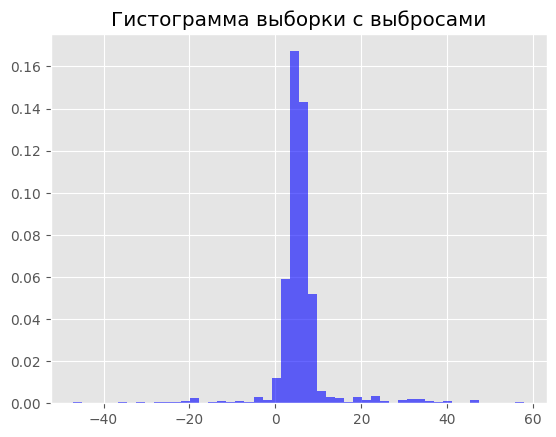

In [ ]:
def generate_contaminated_data(n, mu, sigma, eps=0.1, outlier_multiplier=10):
    is_outlier = np.random.binomial(1, eps, size=n)

    U_usual = np.random.normal(0, 1, size=n)
    U_outlier = np.random.normal(0, outlier_multiplier, size=n)

    U_i = np.where(is_outlier, U_outlier, U_usual)

    X = mu + sigma * U_i
    return X

X_sample = generate_contaminated_data(n=1000, mu=5, sigma=2)
plt.hist(X_sample, bins=50, density=True, alpha=0.6, color='b')
plt.title("Гистограмма выборки с выбросами")
plt.show()

При $n=1000$ и $\varepsilon=0.1$ ожидается около $100$ наблюдений из компоненты выбросов. Для обычных данных стандартное отклонение равно $\sigma=2$, а для загрязняющей компоненты — $10\sigma=20$. Поэтому большинство значений концентрируется около $\mu=5$, но присутствуют отдельные очень удалённые наблюдения. Обе компоненты симметричны относительно нуля, поэтому теоретический центр распределения остаётся равным $\mu=5$.

## Оценки масштаба

Сравниваются выборочное стандартное отклонение, нормированные MAD и IQR, а также две M-оценки масштаба на основе функций потерь Tukey bisquare и truncated square. Нормировки MAD и IQR выбраны для сопоставимости с оценкой стандартного отклонения при нормальных данных. Все оценки затем проверяются на чувствительность к сдвигу, изменению масштаба и загрязнению.


In [ ]:
def madn(x):
    med = np.median(x)
    mad = np.median(np.abs(x - med))
    return mad / 0.6745

def iqrn(x):
    q75, q25 = np.percentile(x, [75, 25])
    return (q75 - q25) / 1.34898

def rho_bisquare_scale(x, c=1.56):
    x_c = x / c
    return np.where(np.abs(x) <= c, 1 - (1 - x_c**2)**3, 1)

np.random.seed(42)
Z = np.random.normal(0, 1, 100000)
delta_bisquare = np.mean(rho_bisquare_scale(Z))

def m_scale_bisquare(x, mu_est=None, c=1.56, max_iter=100, tol=1e-6):
    if mu_est is None:
        mu_est = np.median(x)
    sigma = madn(x)
    for _ in range(max_iter):
        sigma_new = np.sqrt(np.mean(sigma**2 * rho_bisquare_scale((x - mu_est) / sigma, c) / delta_bisquare))
        if np.abs(sigma_new - sigma) < tol:
            return sigma_new
        sigma = sigma_new
    return sigma

def rho_truncated_scale(x, c=1.5):
    return np.minimum(x**2, c**2)

delta_truncated = np.mean(rho_truncated_scale(Z, c=1.5))

def m_scale_truncated(x, mu_est=None, c=1.5, max_iter=100, tol=1e-6):
    if mu_est is None:
        mu_est = np.median(x)
    sigma = madn(x)
    for _ in range(max_iter):
        sigma_new = np.sqrt(np.mean(sigma**2 * rho_truncated_scale((x - mu_est) / sigma, c) / delta_truncated))
        if np.abs(sigma_new - sigma) < tol:
            return sigma_new
        sigma = sigma_new
    return sigma

X_test = np.random.normal(0, 1, 100)
shift_c, scale_c = 10, 3

print("Проверка свойств")
estimators = [
    ("MADN", madn),
    ("IQRN", iqrn),
    ("M-Scale Bisquare", m_scale_bisquare),
    ("M-Scale Truncated", m_scale_truncated)
]

for name, func in estimators:
    base_val = func(X_test)
    shift_val = func(X_test + shift_c)
    scale_val = func(X_test * scale_c)

    print(f"{name}:")
    print(f"  Оригинал: {base_val:.4f}")
    print(f"  Сдвиг (+{shift_c}): {shift_val:.4f} (Ожидаем ~{base_val:.4f})")
    print(f"  Масштаб (*{scale_c}): {scale_val:.4f} (Ожидаем ~{base_val * scale_c:.4f})\n")

Проверка свойств
MADN:
  Оригинал: 1.0697
  Сдвиг (+10): 1.0697 (Ожидаем ~1.0697)
  Масштаб (*3): 3.2091 (Ожидаем ~3.2091)

IQRN:
  Оригинал: 1.0288
  Сдвиг (+10): 1.0288 (Ожидаем ~1.0288)
  Масштаб (*3): 3.0864 (Ожидаем ~3.0864)

M-Scale Bisquare:
  Оригинал: 1.0484
  Сдвиг (+10): 1.0484 (Ожидаем ~1.0484)
  Масштаб (*3): 3.1451 (Ожидаем ~3.1451)

M-Scale Truncated:
  Оригинал: 1.0152
  Сдвиг (+10): 1.0152 (Ожидаем ~1.0152)
  Масштаб (*3): 3.0455 (Ожидаем ~3.0455)



## Поведение оценок масштаба при увеличении выборки

Сначала сравним нормированные оценки на чистых данных из $N(0,1)$ при разных размерах выборки. Для этой модели целевое значение масштаба равно 1.


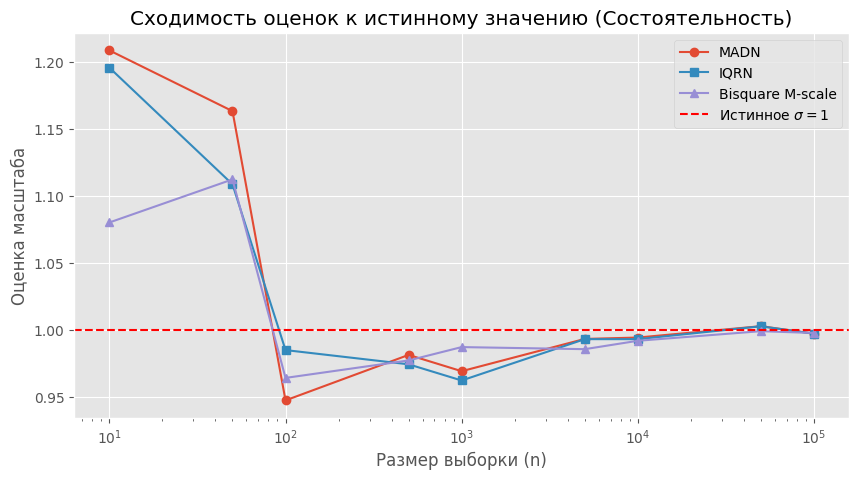

In [ ]:
n_values = [10, 50, 100, 500, 1000, 5000, 10000, 50000, 100000]
madn_vals, iqrn_vals, bisq_vals = [], [], []

for n in n_values:
    clean_sample = np.random.normal(0, 1, n)

    madn_vals.append(madn(clean_sample))
    iqrn_vals.append(iqrn(clean_sample))
    bisq_vals.append(m_scale_bisquare(clean_sample))

plt.figure(figsize=(10, 5))
plt.plot(n_values, madn_vals, marker='o', label='MADN')
plt.plot(n_values, iqrn_vals, marker='s', label='IQRN')
plt.plot(n_values, bisq_vals, marker='^', label='Bisquare M-scale')
plt.axhline(1.0, color='red', linestyle='--', label=r'Истинное $\sigma = 1$')

plt.xscale('log')
plt.xlabel('Размер выборки (n)')
plt.ylabel('Оценка масштаба')
plt.title('Сходимость оценок к истинному значению (Состоятельность)')
plt.legend()
plt.show()

На чистом нормальном распределении график эмпирически иллюстрирует сходимость всех трёх нормированных оценок к истинному значению $\sigma=1$. Fisher-состоятельность относительно нормальной модели обеспечивается выбранными нормировочными константами. При фиксированном засорении $\varepsilon>0$ предельные значения оценок могут отличаться от $\sigma$, поскольку стандартные нормировки рассчитаны для $N(0,1)$.
Это не является ошибкой: в робастной постановке оценки ориентированы на масштаб основной компоненты и должны быть устойчивыми к небольшой доле загрязнения.

Стандартные нормировки MADN, IQRN и M-scale рассчитаны для чистого нормального распределения. Для загрязнённой смеси их предельные значения могут отличаться от масштаба основной компоненты. В следующем сравнении используется отдельная калибровка под выбранную смесь; поэтому результаты этого блока относятся именно к заданной модели загрязнения.


In [ ]:
np.random.seed(123)

mix_sample = generate_contaminated_data(
    n=100000,
    mu=0,
    sigma=1,
    eps=0.1
)

mad_raw = np.median(
    np.abs(mix_sample - np.median(mix_sample))
)

q75, q25 = np.percentile(mix_sample, [75, 25])
iqr_raw = q75 - q25

mad_mix = mad_raw / 0.75355
iqr_mix = iqr_raw / 1.50710

print(f"MAD с калибровкой смеси: {mad_mix:.4f}")
print(f"IQR с калибровкой смеси: {iqr_mix:.4f}")
print("Истинный масштаб sigma = 1")

def m_scale_bisquare_mix(x, mu_est=None, c=1.56,
                         delta_mix=0.54153,
                         max_iter=100, tol=1e-6):
    if mu_est is None:
        mu_est = np.median(x)

    sigma = madn(x)

    for _ in range(max_iter):
        z = (x - mu_est) / sigma
        sigma_new = sigma * np.sqrt(
            np.mean(rho_bisquare_scale(z, c)) / delta_mix
        )

        if abs(sigma_new - sigma) < tol:
            return sigma_new

        sigma = sigma_new

    return sigma

bisquare_mix = m_scale_bisquare_mix(mix_sample)

print(f"Bisquare с калибровкой смеси: {bisquare_mix:.4f}")

MAD с калибровкой смеси: 0.9964
IQR с калибровкой смеси: 0.9964
Истинный масштаб sigma = 1
Bisquare с калибровкой смеси: 0.9978


После перенормировки относительно выбранной смеси MAD, IQR и Bisquare M-scale на большой выборке дают значения, близкие к истинному масштабу $\sigma=1$. Это эмпирически подтверждает корректность предложенной модификации.

## M-оценки положения

Для оценки центра выборки используются M-оценки Huber и Tukey bisquare, решаемые методом итеративного перевзвешивания (IRLS). Масштаб фиксируется по MADN. Параметры $k=1.345$ для Huber и $c=4.685$ для bisquare задают область, в которой наблюдения получают полный вес; далее вес уменьшается, а у bisquare для достаточно удалённых точек становится нулевым.


In [ ]:
def huber_psi(x, k=1.345):
    return np.where(np.abs(x) <= k, x, k * np.sign(x))

def huber_weight(x, k=1.345):
    x_safe = np.where(x == 0, 1e-8, x)
    return huber_psi(x_safe, k) / x_safe

def huber_psi_prime(x, k=1.345):
    return np.where(np.abs(x) <= k, 1.0, 0.0)

def bisquare_psi(x, c=4.685):
    return np.where(np.abs(x) <= c, x * (1 - (x/c)**2)**2, 0)

def bisquare_weight(x, c=4.685):
    return np.where(np.abs(x) <= c, (1 - (x/c)**2)**2, 0)

def bisquare_psi_prime(x, c=4.685):
    return np.where(np.abs(x) <= c, (1 - (x/c)**2) * (1 - 5*(x/c)**2), 0)

def m_estimate_location(x, scale_est, weight_func, param, max_iter=100, tol=1e-6):
    mu = np.median(x)

    for _ in range(max_iter):
        z = (x - mu) / scale_est
        w = weight_func(z, param)
        mu_new = np.sum(w * x) / np.sum(w)

        if np.abs(mu_new - mu) < tol:
            break
        mu = mu_new
    return mu

def asymp_variance(x, mu_est, scale_est, psi_func, psi_prime_func, param):
    n = len(x)
    z = (x - mu_est) / scale_est

    num = np.mean(psi_func(z, param)**2)
    den = (np.mean(psi_prime_func(z, param)))**2

    return (num / den) * (scale_est**2 / n)

scale_fixed = madn(X_sample)

mu_huber = m_estimate_location(X_sample, scale_fixed, huber_weight, param=1.345)
var_huber = asymp_variance(X_sample, mu_huber, scale_fixed, huber_psi, huber_psi_prime, param=1.345)

mu_bisquare = m_estimate_location(X_sample, scale_fixed, bisquare_weight, param=4.685)
var_bisquare = asymp_variance(X_sample, mu_bisquare, scale_fixed, bisquare_psi, bisquare_psi_prime, param=4.685)

print(f"Истинное mu = 5.0")
print(f"Обычное среднее (mean) = {np.mean(X_sample):.4f}")
print(f"Huber mu: {mu_huber:.4f}, Асимпт. дисперсия: {var_huber:.6f}")
print(f"Bisquare mu: {mu_bisquare:.4f}, Асимпт. дисперсия: {var_bisquare:.6f}")

Истинное mu = 5.0
Обычное среднее (mean) = 5.6829
Huber mu: 5.3174, Асимпт. дисперсия: 0.005782
Bisquare mu: 5.2366, Асимпт. дисперсия: 0.004830


На данной реализации выборочное среднее $5.6829$ оказалось дальше от истинного значения $\mu=5$, чем робастные оценки. При этом симметричное засорение не создаёт систематического смещения среднего: его основная проблема — существенное увеличение дисперсии. Huber дал оценку $5.3174$, а Bisquare — $5.2366$. Для данной выборки Bisquare также имеет меньшую численную оценку асимптотической дисперсии.

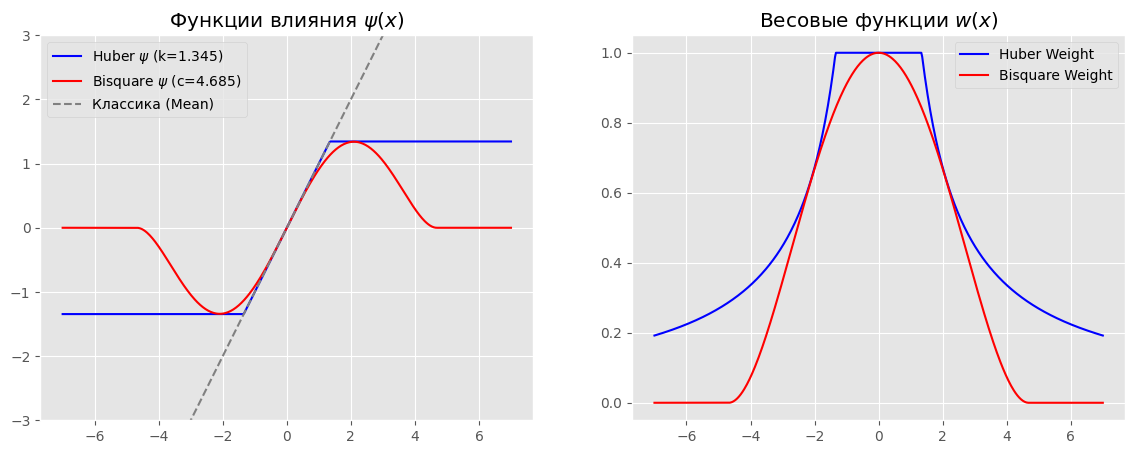

In [ ]:
x_plot = np.linspace(-7, 7, 500)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(x_plot, huber_psi(x_plot, 1.345), label=r'Huber $\psi$ (k=1.345)', color='blue')
axes[0].plot(x_plot, bisquare_psi(x_plot, 4.685), label=r'Bisquare $\psi$ (c=4.685)', color='red')
axes[0].plot(x_plot, x_plot, label='Классика (Mean)', color='gray', linestyle='--')
axes[0].set_title(r"Функции влияния $\psi(x)$")
axes[0].set_ylim(-3, 3)
axes[0].legend()

axes[1].plot(x_plot, huber_weight(x_plot, 1.345), label='Huber Weight', color='blue')
axes[1].plot(x_plot, bisquare_weight(x_plot, 4.685), label='Bisquare Weight', color='red')
axes[1].set_title("Весовые функции $w(x)$")
axes[1].legend()

plt.show()

Для классического среднего вес всех наблюдений равен $1$, однако функция влияния $\psi(x)=x$ не ограничена, поэтому влияние наблюдения растёт вместе с величиной отклонения. У Huber функция $\psi$ ограничена, поэтому влияние больших выбросов перестаёт расти. У Bisquare вес становится равным нулю при $|x|>c$, поэтому достаточно удалённые наблюдения полностью исключаются из оценки.

## Влияние настроечных параметров

Параметры $k$ у Huber и $c$ у Tukey bisquare задают порог, после которого уменьшается влияние наблюдений. Сравним оценки положения и численную plug-in оценку асимптотической дисперсии для нескольких значений параметров.


In [ ]:
k_values = [0.5, 1.0, 1.345, 2.0, 3.0]
c_values = [1.5, 3.0, 4.685, 6.0, 8.0]

print("Функция Губера (влияние параметра k)")
for k in k_values:
    mu_est = m_estimate_location(X_sample, scale_fixed, huber_weight, param=k)
    var_est = asymp_variance(X_sample, mu_est, scale_fixed, huber_psi, huber_psi_prime, param=k)
    print(f"k = {k:5.3f} | Оценка mu: {mu_est:.4f} | Асимпт. дисперсия: {var_est:.6f}")

print("\nФункция Bisquare (влияние параметра c)")
for c in c_values:
    mu_est = m_estimate_location(X_sample, scale_fixed, bisquare_weight, param=c)
    var_est = asymp_variance(X_sample, mu_est, scale_fixed, bisquare_psi, bisquare_psi_prime, param=c)
    print(f"c = {c:5.3f} | Оценка mu: {mu_est:.4f} | Асимпт. дисперсия: {var_est:.6f}")

Функция Губера (влияние параметра k)
k = 0.500 | Оценка mu: 5.2679 | Асимпт. дисперсия: 0.005879
k = 1.000 | Оценка mu: 5.2952 | Асимпт. дисперсия: 0.005707
k = 1.345 | Оценка mu: 5.3174 | Асимпт. дисперсия: 0.005782
k = 2.000 | Оценка mu: 5.3398 | Асимпт. дисперсия: 0.006493
k = 3.000 | Оценка mu: 5.3764 | Асимпт. дисперсия: 0.008642

Функция Bisquare (влияние параметра c)
c = 1.500 | Оценка mu: 5.1332 | Асимпт. дисперсия: 0.011360
c = 3.000 | Оценка mu: 5.2410 | Асимпт. дисперсия: 0.005301
c = 4.685 | Оценка mu: 5.2366 | Асимпт. дисперсия: 0.004830
c = 6.000 | Оценка mu: 5.2386 | Асимпт. дисперсия: 0.004968
c = 8.000 | Оценка mu: 5.2528 | Асимпт. дисперсия: 0.005459




1. **Функция Губера $k$:** Чем больше $k$, тем слабее защита от выбросов. При больших $k$ алгоритм работает почти как обычное среднее: оценка отдаляется от истины 5.0, а дисперсия растет.

2. **Функция Bisquare $c$:** при слишком маленьком c=1.5 отбрасывается много наблюдений, поэтому асимптотическая дисперсия существенно возрастает. Хотя на данной реализации оценка оказалась близка к истинному $\mu=5$, это не означает, что такое значение c является оптимальным. Среди рассмотренных значений минимальная оценка асимптотической дисперсии получена при c=4.685. При дальнейшем увеличении c влияние выбросов возрастает, и дисперсия снова увеличивается.

3. **Итог:** На наших данных Bisquare справился лучше Губера (дисперсия меньше, оценка точнее). Это логично: Bisquare *полностью обнуляет* вес далеких выбросов, тогда как Губер всё равно оставляет им небольшое влияние.

## Совместная оценка положения и масштаба

В этом эксперименте положение $\mu$ и масштаб $\sigma$ оцениваются совместно: робастная оценка масштаба обновляется вместе с M-оценкой положения. Сравниваются два сочетания функций — truncated scale с Huber и bisquare scale с bisquare — при нескольких долях загрязнения.


In [ ]:
def simultaneous_m_estimates(
    x,
    loc_weight_func,
    loc_param,
    scale_rho_func,
    scale_delta,
    max_iter=100,
    tol=1e-5
):
    mu = np.median(x)
    sigma = madn(x)

    for _ in range(max_iter):
        mu_old = mu
        sigma_old = sigma

        z_scale = (x - mu) / sigma
        sigma = sigma * np.sqrt(
            np.mean(scale_rho_func(z_scale)) / scale_delta
        )

        z = (x - mu) / sigma
        w = loc_weight_func(z, loc_param)
        mu = np.sum(w * x) / np.sum(w)

        if abs(mu - mu_old) < tol and abs(sigma - sigma_old) < tol:
            break

    return mu, sigma

results = []
mu_true, sigma_true = 10, 2
epsilons = [0.0, 0.05, 0.20]

for eps in epsilons:
    data = generate_contaminated_data(n=500, mu=mu_true, sigma=sigma_true, eps=eps)

    mean_classic = np.mean(data)
    std_classic = np.std(data)

    med = np.median(data)
    scale_madn = madn(data)

    mu_sim_h, sig_sim_h = simultaneous_m_estimates(
      data,
      huber_weight,
      1.345,
      rho_truncated_scale,
      delta_truncated
    )

    mu_sim_b, sig_sim_b = simultaneous_m_estimates(
      data,
      bisquare_weight,
      4.685,
      rho_bisquare_scale,
      delta_bisquare
    )

    results.append({
        "Epsilon (Выбросы)": f"{eps*100}%",
        "Mean (Classic)": mean_classic,
        "Std (Classic)": std_classic,
        "Median": med,
        "MADN": scale_madn,
        "Huber  + Truncated: \u03bc": mu_sim_h,
        "Huber  + Truncated: \u03c3": sig_sim_h,
        "Bisquare: \u03bc": mu_sim_b,
        "Bisquare: \u03c3": sig_sim_b,
    })

df_results = pd.DataFrame(results)
display(df_results.round(4))

,Epsilon (Выбросы),Mean (Classic),Std (Classic),Median,MADN,Huber + Truncated: μ,Huber + Truncated: σ,Bisquare: μ,Bisquare: σ
0,0.0%,10.1222,2.0408,10.1999,2.0184,10.1250,2.0767,10.1236,2.0854
1,5.0%,9.9351,4.4353,9.8074,2.0894,9.8397,2.1163,9.8143,2.0845
2,20.0%,10.0438,9.5053,10.2807,2.5752,10.1436,2.8590,10.2025,2.6426


При 5% засорения классическое среднее остаётся близким к истинному $\mu=10$, однако стандартное отклонение возрастает с 2.04 до 4.44. Робастные оценки масштаба при этом остаются близкими к истинному значению $\sigma=2$: 2.12 для Huber + Truncated и 2.08 для Bisquare. При 20% засорения оценки положения также остаются близкими к $\mu=10$, а оценки масштаба возрастают до 2.86 и 2.64 соответственно. При этом классическое стандартное отклонение достигает 9.51. Таким образом, робастные оценки значительно слабее реагируют на увеличение доли выбросов.

## Сравнение методом Монте-Карло

Для 500 независимых выборок с 10% загрязнения сравниваются классическое среднее и робастные M-оценки. Основной критерий — эмпирический разброс оценок положения между симуляциями.


Эмпирическая дисперсия оценок (по 500 выборкам):
Классическое среднее: 0.060349
Huber M-оценка:      0.008288
Bisquare M-оценка:   0.006596
Среднее Mean:     -0.0130
Среднее Huber:    -0.0076
Среднее Bisquare: -0.0069
Дисперсия Mean / Huber: 7.28 раза
Дисперсия Mean / Bisquare: 9.15 раза


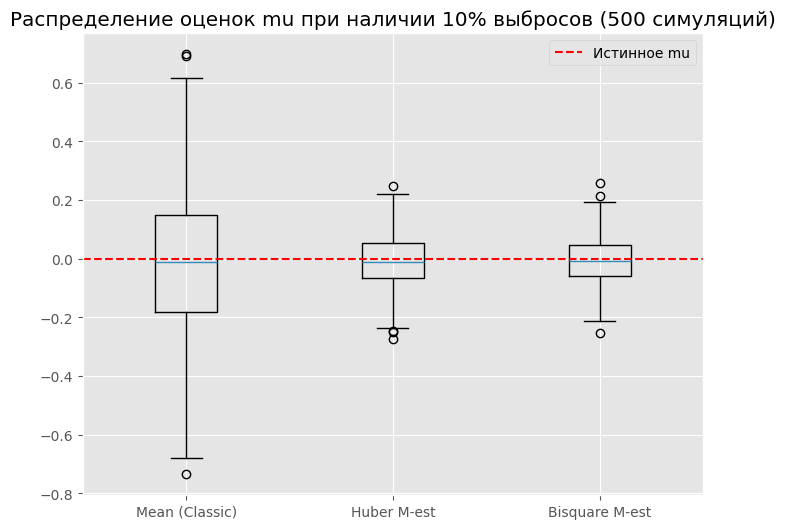

In [ ]:
n_simulations = 500
n_size = 200
mu_true = 0
sigma_true = 1

mu_classic_list = []
mu_huber_list = []
mu_bisquare_list = []

for i in range(n_simulations):
    sample = generate_contaminated_data(n_size, mu_true, sigma_true, eps=0.1)

    mu_classic_list.append(np.mean(sample))

    mu_h, _ = simultaneous_m_estimates(
      sample,
      huber_weight,
      1.345,
      rho_truncated_scale,
      delta_truncated
    )

    mu_b, _ = simultaneous_m_estimates(
        sample,
        bisquare_weight,
        4.685,
        rho_bisquare_scale,
        delta_bisquare
    )

    mu_huber_list.append(mu_h)
    mu_bisquare_list.append(mu_b)

print("Эмпирическая дисперсия оценок (по 500 выборкам):")
print(f"Классическое среднее: {np.var(mu_classic_list):.6f}")
print(f"Huber M-оценка:      {np.var(mu_huber_list):.6f}")
print(f"Bisquare M-оценка:   {np.var(mu_bisquare_list):.6f}")
print(f"Среднее Mean:     {np.mean(mu_classic_list):.4f}")
print(f"Среднее Huber:    {np.mean(mu_huber_list):.4f}")
print(f"Среднее Bisquare: {np.mean(mu_bisquare_list):.4f}")

var_mean = np.var(mu_classic_list)
var_huber = np.var(mu_huber_list)
var_bisquare = np.var(mu_bisquare_list)

print(f"Дисперсия Mean / Huber: {var_mean / var_huber:.2f} раза")
print(f"Дисперсия Mean / Bisquare: {var_mean / var_bisquare:.2f} раза")

plt.figure(figsize=(8, 6))
plt.boxplot([mu_classic_list, mu_huber_list, mu_bisquare_list],
            tick_labels=['Mean (Classic)', 'Huber M-est', 'Bisquare M-est'])
plt.axhline(mu_true, color='red', linestyle='--', label='Истинное mu')
plt.title("Распределение оценок mu при наличии 10% выбросов (500 симуляций)")
plt.legend()
plt.show()

Эмпирическая дисперсия классического среднего примерно в 7.3 раза выше, чем у Huber, и в 9.2 раза выше, чем у Bisquare.Средние значения всех трёх оценок остаются близкими к истинному $\mu=0$, что соответствует симметрии модели. Следовательно, преимущество робастных M-оценок в данном эксперименте состоит прежде всего в существенно меньшем разбросе. Среди рассмотренных методов минимальную эмпирическую дисперсию показала оценка Bisquare.

# Выводы

В заданной модели загрязнения робастные оценки масштаба слабее реагировали на выбросы, чем выборочное стандартное отклонение. Среди рассмотренных оценок положения Huber и Tukey bisquare показали меньший эмпирический разброс, чем среднее; на этих симуляциях минимальный разброс был у bisquare.

Результат зависит от доли и распределения загрязнения, а также от настроечных параметров. Поэтому выводы относятся к рассмотренным сценариям и не означают, что один метод будет лучшим для любых данных.
